In [1]:
import glob

import matplotlib.pyplot as plt
import numpy as np
import tifffile

from natsort import natsorted
from sklearn.linear_model import LinearRegression

%matplotlib inline
plt.style.use('seaborn-v0_8-notebook')

data_dir = 'data/Basler_RAAC_2024_09_26/'

def load_tiff_directory(directory_path: str):
    tiff_paths = natsorted(glob.glob(directory_path + '*.tif*'))
    curr_img = tifffile.imread(tiff_paths[0])
    images = np.empty((len(tiff_paths), curr_img.shape[0], curr_img.shape[1]), dtype=np.float32)
    images[0] = curr_img

    for i, tiff_path in enumerate(tiff_paths[1:]):
        images[i+1] = tifffile.imread(tiff_path)
        
    return images

**A note on units:** the Basler TIFFs store 12-bit values shifted left by 4 bits, so every value is a multiple of 16 and full scale is 65520. All counts below are in these 16-bit units unless stated otherwise. Divide by 16 to get 12-bit counts.

## Measure readout noise

### Data: 
A sequence of images (∼ 100) from the camera with NO light hitting the detector at an extremely short exposure time (∼ 1 ms).

### Exercise instructions:
Measure the standard deviation of each pixels value across the movie (use ImageJ). What is the average noise (standard deviation in counts) across pixels?

In [2]:
def measure_readout_noise(im_data, downsample=5):
    im_data = im_data[:, ::downsample, ::downsample]
    
    return np.std(im_data, axis=0, ddof=1, dtype=np.float32)

def calc_plot_readout_noise(im_data, axis, downsample=5):
    pix_dev = measure_readout_noise(im_data, downsample)
    mean_dev = np.mean(pix_dev, dtype=np.float32)
    
    axis.hist(pix_dev.flatten(), bins=100)
    axis.axvline(mean_dev, color='r', linestyle='--')
    axis.text(0.8, 0.8, f'Mean: {mean_dev:.3f}', ha='center', va='center', transform=axis.transAxes)
    axis.set_ylabel('Count')
    axis.set_xlabel('Standard deviation')
    
    return mean_dev

def plot_readout_noise_multiple_gain(gain_levels: list[str], path_stub: str,  downsample: int):
    num_plots = (len(gain_levels) + 1)// 2
    
    fig, ax = plt.subplots(num_plots, 2, figsize=(14, 14))
    mean_devs = []
    bias = []
    
    for i, gain in enumerate(gain_levels):
        read_noise_images = load_tiff_directory(f'{path_stub}{gain}dB/')
        bias.append(np.mean(read_noise_images, dtype=np.float32))
        print(f'{gain} dB: {np.mean(read_noise_images == 0):.1%} of values are clipped at 0')
        mean_devs.append(calc_plot_readout_noise(read_noise_images, ax[i//2][i%2], downsample))
        ax[i//2][i%2].set_title(f'{gain}dB')
        
    plt.show()
    
    fig, ax = plt.subplots()
    ax.plot(gain_levels, mean_devs, marker='o')
    ax.set_xlabel('Gain (dB)')
    ax.set_ylabel('Read noise (counts)')
    plt.show()
    
    return mean_devs, bias

Let's plot the readout noise for the Basler camera at different gain levels.

0 dB: 92.0% of values are clipped at 0


1 dB: 89.4% of values are clipped at 0


12 dB: 49.1% of values are clipped at 0


24 dB: 30.4% of values are clipped at 0


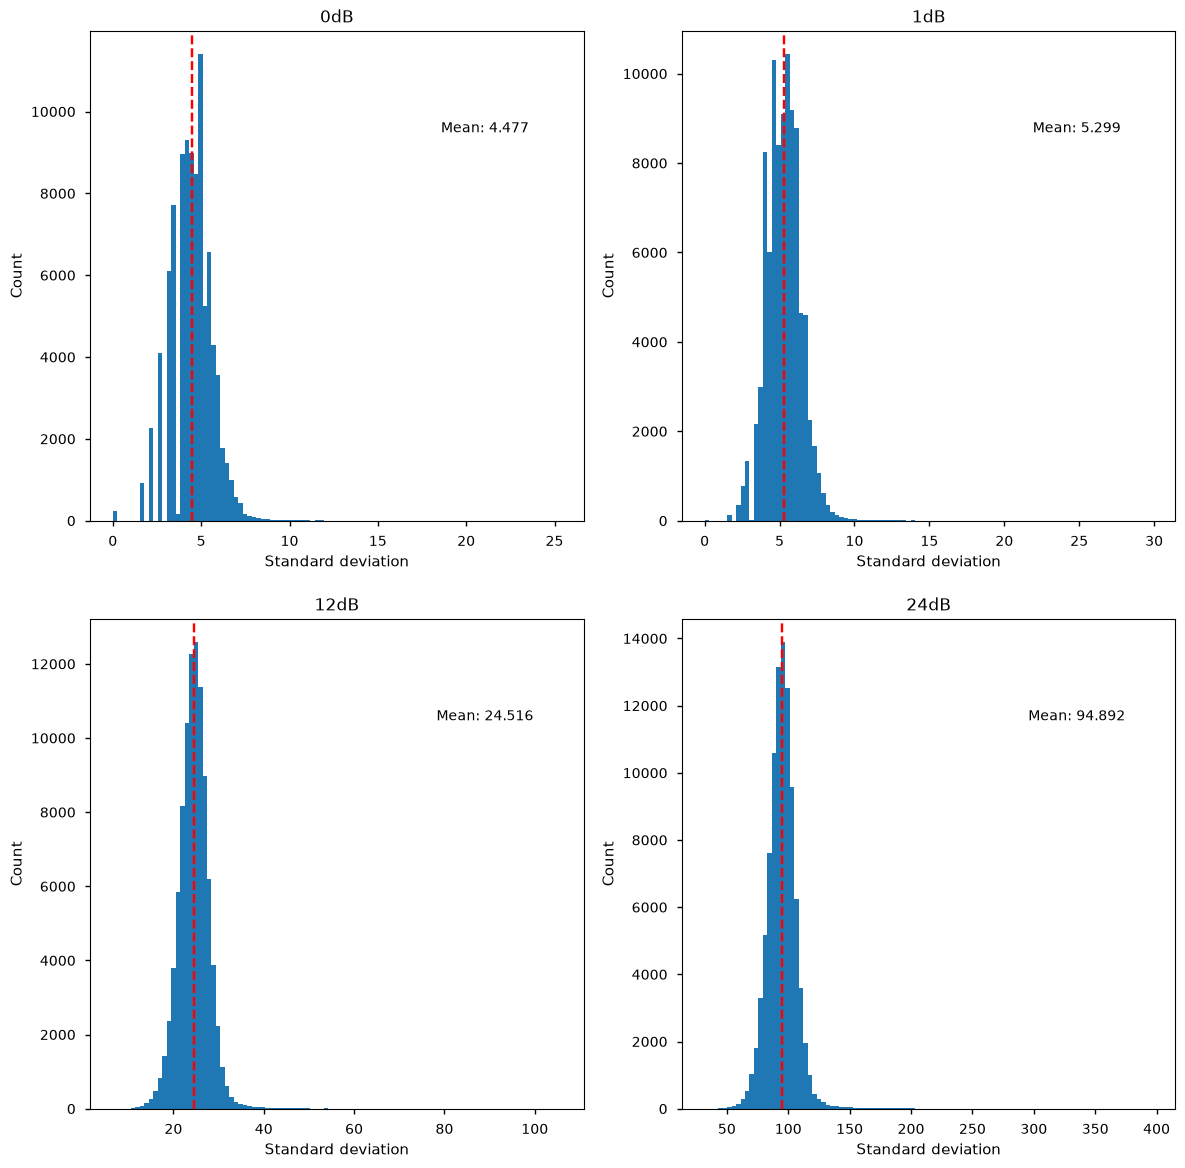

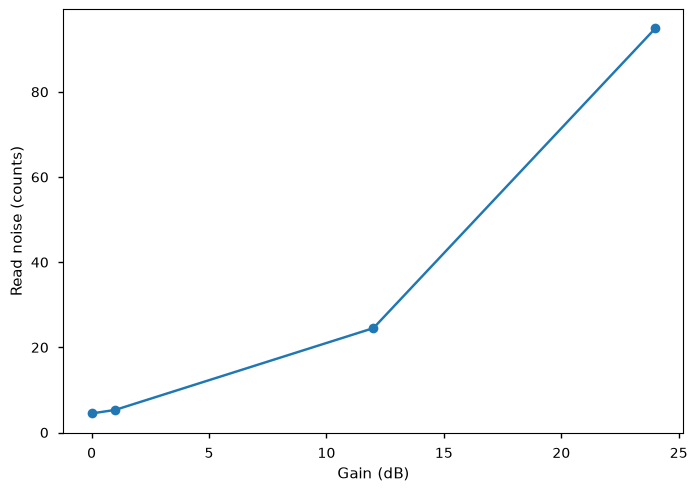

In [3]:
gain_levels = [0, 1, 12, 24]
read_noise_stub = f'{data_dir}read_noise/40us_'
downsample_by = 5

clipped_read_noise, read_set_bias = plot_readout_noise_multiple_gain(gain_levels, read_noise_stub, downsample_by)

In [4]:
def read_noise_from_frame_pair(directory_path):
    frames = load_tiff_directory(directory_path)
    # The fixed pattern cancels in the difference, and subtracting two frames doubles the variance
    return np.std(frames[0] - frames[1]) / np.sqrt(2)

dark_counts_stub = f'{data_dir}dark_noise'
read_noise = [read_noise_from_frame_pair(f'{dark_counts_stub}/{gain}dB/') for gain in gain_levels]

for gain, clipped, unclipped in zip(gain_levels, clipped_read_noise, read_noise):
    print(f'{gain} dB: {clipped:.2f} counts from the clipped movie, {unclipped:.2f} counts from the unclipped dark frames')

0 dB: 4.48 counts from the clipped movie, 13.04 counts from the unclipped dark frames
1 dB: 5.30 counts from the clipped movie, 14.09 counts from the unclipped dark frames
12 dB: 24.52 counts from the clipped movie, 37.21 counts from the unclipped dark frames
24 dB: 94.89 counts from the clipped movie, 125.75 counts from the unclipped dark frames


### Conclusions

**The read noise movies cannot be used to measure read noise directly.** They were acquired with no offset, so 30-92% of values are clipped at 0, depending on the gain. This is the problem the instructions warn about: clipping removes the negative fluctuations, so the standard deviation comes out too low.

The dark frames do have an offset and contain no clipped values, so we estimate read noise from them. Taking the difference of the two shortest exposures (40 µs and 1 ms) removes the fixed pattern, and dark counts are negligible at these exposures.

| Gain | Average std of clipped movie (counts) | RMS read noise from dark frames (counts) |
|---|---|---|
| 0 dB | 4.48 | 13.04 |
| 1 dB | 5.30 | 14.09 |
| 12 dB | 24.52 | 37.21 |
| 24 dB | 94.89 | 125.75 |

We use the dark frame values from here on. Read noise in counts increases with gain because the amplifier also amplifies noise generated before it.

## Measure dark counts

### Data:
A sequence of images (∼ 100) from the camera with NO light hitting the detector at a range of exposure times.

### Exercise instructions:
Measure the Mean number of counts in each image. 

Do the counts increase with increasing exposure time? How many counts/pixel/second do you observe? Hint: Remember to subtract the Bias Level, the average value (in counts) appearing in the image following a 0-second exposure. (This is an offset added to each image by the camera manufacturers and does not reflect the incident light level.)

In [5]:
def measure_dark_counts(im_data):
    return np.mean(im_data, axis=(1,2), dtype=np.float32)

def calc_plot_dark_counts(im_data, exposures):
    dark_counts = measure_dark_counts(im_data)
    bias = dark_counts[0]
    subtracted_counts = dark_counts - bias
    
    model_dark_noise = LinearRegression()
    model_dark_noise.fit(exposures.reshape(-1, 1), subtracted_counts)
    
    print(f'The slope of the dark noise is {model_dark_noise.coef_}')
    print(f'The y-intercept of the dark noise is {model_dark_noise.intercept_}')
    
    fig, ax = plt.subplots()
    ax.plot(exposures, subtracted_counts, marker='o')
    ax.set_xlabel('Exposure time (s)')
    ax.set_ylabel('Mean counts')
    plt.show()
    
    return dark_counts, subtracted_counts, model_dark_noise

Dark counts for 0dB
The slope of the dark noise is [16.60650535]
The y-intercept of the dark noise is -0.1702798639857548


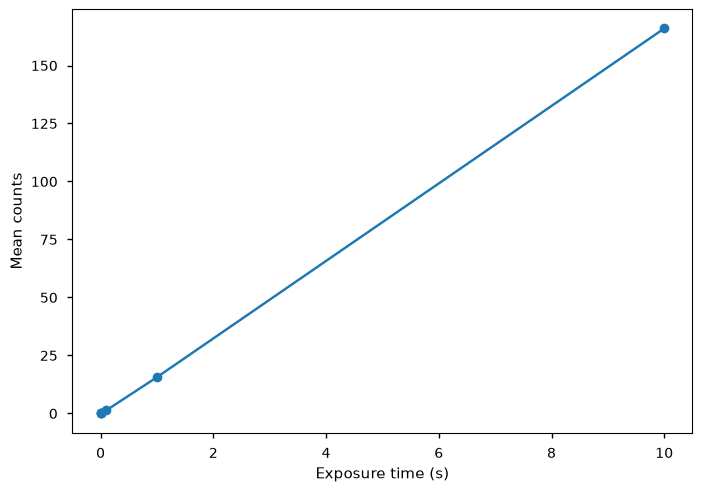

Dark counts for 1dB
The slope of the dark noise is [23.39925949]
The y-intercept of the dark noise is -0.06203645983298145


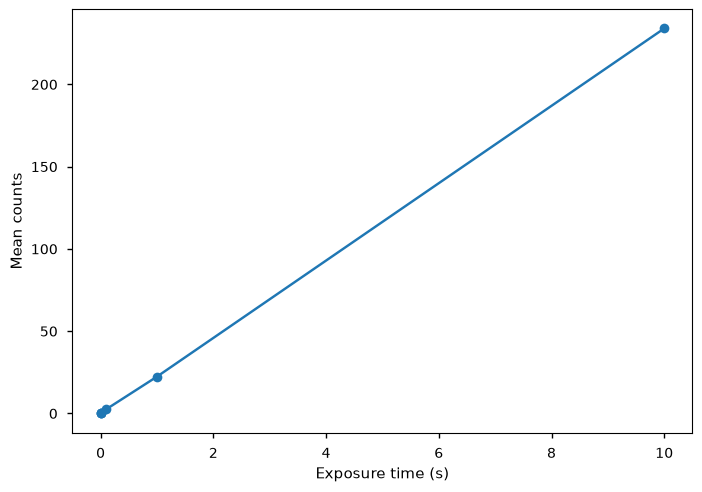

Dark counts for 12dB
The slope of the dark noise is [92.98868483]
The y-intercept of the dark noise is -1.287120872130913


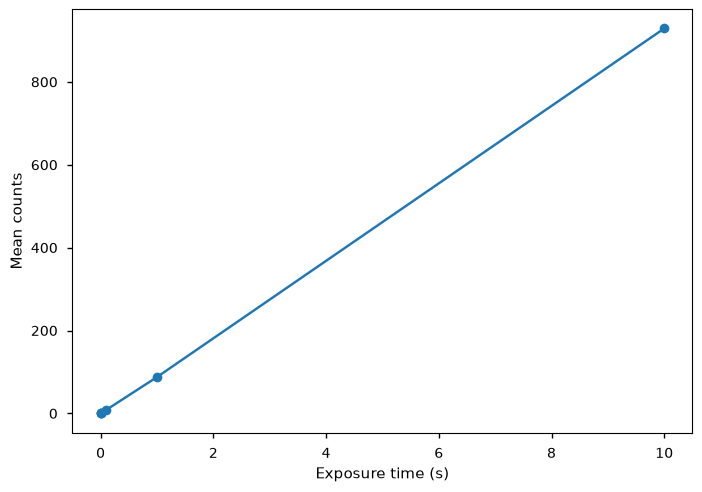

Dark counts for 24dB


The slope of the dark noise is [449.6359728]
The y-intercept of the dark noise is -5.26610316877634


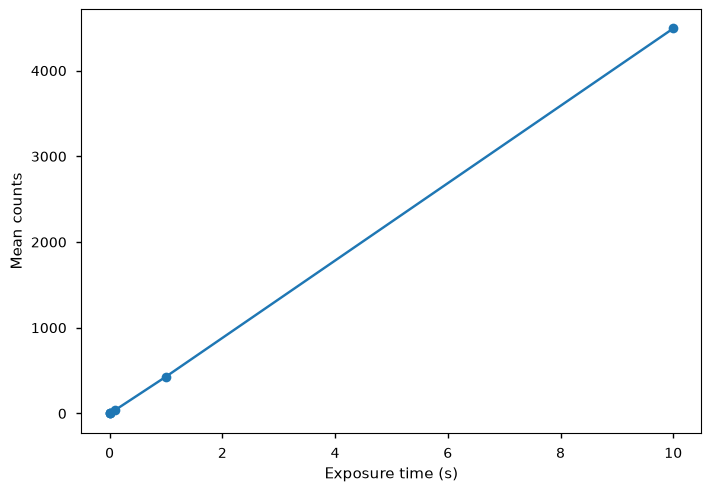

In [6]:
dark_count_results = []

for i, gain in enumerate(gain_levels):
    print(f'Dark counts for {gain}dB')
    full_path = f'{dark_counts_stub}/{gain}dB/'
    dark_images = load_tiff_directory(full_path)

    exposures = np.array([0.00004, 0.001, 0.01, 0.1, 1, 10])
        
    dark_count_results.append(calc_plot_dark_counts(dark_images, exposures))
    

### Conclusions

**Yes, the counts increase with exposure time.** They change by less than 2 counts up to 10 ms, then grow roughly linearly with exposure time. The fit is dominated by the 10 s point because the exposures are spaced logarithmically. Each exposure is a single frame, and we assume the file names give the exposure in ms, with `0` being the 40 µs minimum.

| Gain | Bias (counts) | Dark counts (counts/pixel/s) | Dark counts (12-bit counts/pixel/s) |
|---|---|---|---|
| 0 dB | 150.7 | 16.6 | 1.04 |
| 1 dB | 151.2 | 23.4 | 1.46 |
| 12 dB | 297.7 | 93.0 | 5.81 |
| 24 dB | 1117.1 | 449.6 | 28.1 |

The fit intercepts are close to 0, as expected after subtracting the bias. Dark counts rise with gain because electrons are amplified whatever their source. The rise is not exactly proportional to the nominal gain, though: 0 dB to 12 dB is a factor of 5.6 rather than 3.98. These data cannot tell us why. Using the gain measured below, 12 dB corresponds to about 11.6 e-/pixel/s.

## Compute the dynamic range of the camera

First determine the cameras full well capacity (saturation value) in counts after bias removal.

Use a long exposure and expose the camera to a bright light source. What value are saturated
pixels assigned? Use the formula below to compute the cameras dynamic range (the number of
individually discernible light levels) for a fixed exposure.
$$
\text{Dynamic Range} = (\text{Saturation} - \text{Dark counts}) / \text{Read-out noise}
$$
Note: Use bias subtracted values for both Saturation and Dark counts.
Compare your results to the cameras technical specification sheet.

In [7]:
# The TIFFs store 12-bit values shifted left by 4 bits, so full scale is 4095 * 16 = 65520, not 65535.
# The 10 s dark frames contain saturated hot pixels, so we can read this value from the data.
saturated_value = int(load_tiff_directory(f'{dark_counts_stub}/{gain_levels[-1]}dB/').max())
print(f'Saturated pixels are assigned the value {saturated_value}')

exposure_index = 1
dynamic_range = []

for i, gain in enumerate(gain_levels):
    # dark_count_results[i][0][0] is the bias for the given gain
    bias = dark_count_results[i][0][0]
    sat_value = saturated_value - bias
    dark_count = dark_count_results[i][1][exposure_index]
    dynamic_range.append((sat_value - dark_count) / read_noise[i])

    print(f'{gain} dB: saturation after bias removal is {sat_value:.0f} counts, '
          f'dark counts at {exposures[exposure_index]*1000:.2f} ms are {dark_count:.2f}, '
          f'dynamic range is {dynamic_range[i]:.0f}:1 ({20 * np.log10(dynamic_range[i]):.1f} dB)')

Saturated pixels are assigned the value 65520
0 dB: saturation after bias removal is 65369 counts, dark counts at 1.00 ms are 0.24, dynamic range is 5012:1 (74.0 dB)
1 dB: saturation after bias removal is 65369 counts, dark counts at 1.00 ms are 0.34, dynamic range is 4638:1 (73.3 dB)
12 dB: saturation after bias removal is 65222 counts, dark counts at 1.00 ms are -0.13, dynamic range is 1753:1 (64.9 dB)
24 dB: saturation after bias removal is 64403 counts, dark counts at 1.00 ms are 0.80, dynamic range is 512:1 (54.2 dB)


### Conclusions

**Saturated pixels are assigned the value 65520**, which is 4095 in 12-bit counts. We read this from saturated hot pixels in the 10 s dark frames, and it also appears in the 100 ms, 12 dB shot noise movie.

| Gain | Saturation after bias removal (counts) | Dynamic range | Dynamic range (dB) |
|---|---|---|---|
| 0 dB | 65369 | 5012:1 | 74.0 |
| 1 dB | 65369 | 4638:1 | 73.3 |
| 12 dB | 65222 | 1753:1 | 64.9 |
| 24 dB | 64403 | 512:1 | 54.2 |

**Dynamic range is highest at the lowest gain.** Increasing the gain raises read noise in counts, while the digitizer's maximum value stays fixed. The comparison with the specification sheet is at the end of the notebook.

## Measure shot noise

### Data:
Acquire sequences of images (100) with the camera exposed to a wide distribution of brightness values. You can do this in two ways:
- Use a range of pixel intensities within an image: structured sample illuminated at a fixed intensity. Measure the mean and standard deviation for each pixel across the image sequence.
- Use a range of illumination intensities: same pixel, across different LED currents. Measure the mean and standard deviation of a select pixel across the images acquired at various illumination intensities.

Use 1 second exposure time for either option. The illumination light must be stable; use an LED in an enclosed container (to avoid background changes).

The data used here follow the first option, but were acquired at 10 ms and 100 ms rather than 1 second.

### Exercise instructions:
Plot the variance, i.e. standard deviation squared (Y axis) vs. mean (X axis) for different brightness levels. Fit a line. Determine the detectors gain (counts per photoelectron):

Hint: Remember to subtract out the Bias Level measured above. 

Note: The slope of the line will be the Gain of your camera.

Where does the fit line intersect the y-axis? Does this make sense?

In [8]:
def drop_repeated_frames(images):
    is_new_frame = np.any(images[1:] != images[:-1], axis=(1, 2))
    return images[np.r_[True, is_new_frame]]

def measure_shot_noise(image_path, offset):
    shot_image = drop_repeated_frames(load_tiff_directory(image_path)) - offset

    # Rescale each frame to the same mean so that frame-to-frame changes in the
    # illumination are not counted as shot noise.
    frame_means = np.mean(shot_image, axis=(1, 2), dtype=np.float64)
    print(f'{shot_image.shape[0]} unique frames, frame means vary by {np.std(frame_means, ddof=1) / np.mean(frame_means):.2%}')
    shot_image = shot_image / (frame_means / np.mean(frame_means)).reshape(-1, 1, 1).astype(np.float32)

    mean = np.mean(shot_image, axis=0, dtype=np.float32).reshape(-1, 1)
    var = np.var(shot_image, axis=0, ddof=1, dtype=np.float32).reshape(-1, 1)

    return mean, var

def calculate_plot_shot_noise(image_path, offset, downsample=5):
    mean, var = measure_shot_noise(image_path, offset)

    model = LinearRegression()
    model.fit(mean, var)

    # The intercept is an extrapolation, so check how much it depends on the fit range
    dim_pixels = mean[:, 0] < 0.35 * mean.max()
    model_dim = LinearRegression()
    model_dim.fit(mean[dim_pixels], var[dim_pixels])

    best_fit = model.predict(mean)

    print(f'The gain of the camera is {model.coef_[0][0]:.3f} counts/e-')
    print(f'The y-intercept is {model.intercept_[0]:.3f}')
    print(f'Fitting the dimmest pixels only, the gain is {model_dim.coef_[0][0]:.3f} counts/e- and the y-intercept is {model_dim.intercept_[0]:.3f}')
    print(f'The dimmest pixel has a mean of {mean.min():.0f} counts')

    fig, ax = plt.subplots()
    ax.scatter(mean[::downsample], var[::downsample])
    ax.plot(mean, best_fit, color='r', linestyle='--')
    ax.set_xlabel('Mean counts')
    ax.set_ylabel('Variance')

    plt.show()

    return model.coef_[0][0], model.intercept_[0]

Shot noise for 12dB 10 ms exposure


114 unique frames, frame means vary by 0.05%


The gain of the camera is 7.991 counts/e-
The y-intercept is 4369.188
Fitting the dimmest pixels only, the gain is 8.194 counts/e- and the y-intercept is 1692.094
The dimmest pixel has a mean of 4327 counts


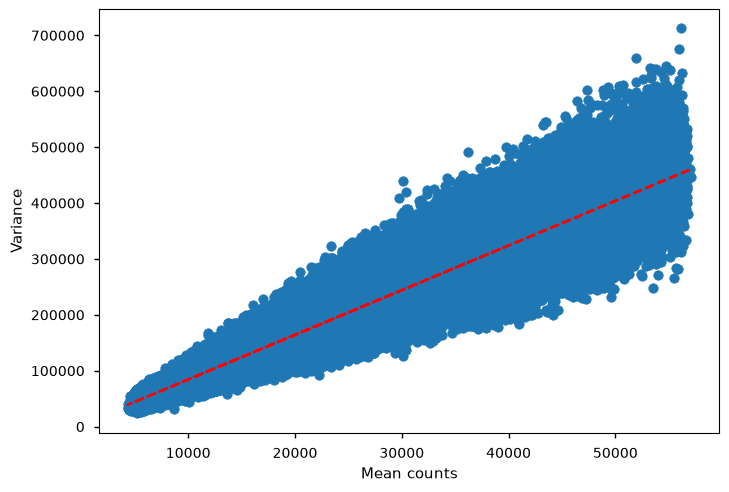

Shot noise for 12dB 100 ms exposure


44 unique frames, frame means vary by 0.20%


The gain of the camera is 8.067 counts/e-
The y-intercept is 2642.578
Fitting the dimmest pixels only, the gain is 8.187 counts/e- and the y-intercept is 2034.602
The dimmest pixel has a mean of 4861 counts


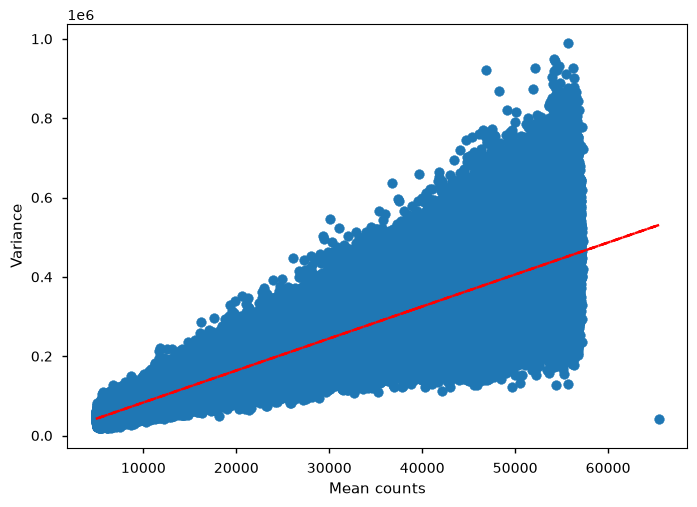

In [9]:
# The shot noise movies appear to come from the same session as the read noise movies (1216 rows, same
# file naming), not the dark frames (1208 rows), so we use the bias of the read noise set at 12 dB.
bias = read_set_bias[2]

print("Shot noise for 12dB 10 ms exposure")
shot_noise_10ms_12db_path = f'{data_dir}shot_noise/10ms_12dB/'
shot_noise_10ms_12db_gain, shot_noise_10ms_12db_intercept = calculate_plot_shot_noise(shot_noise_10ms_12db_path, bias)

print("Shot noise for 12dB 100 ms exposure")
shot_noise_100ms_12db_path = f'{data_dir}shot_noise/100ms_12dB/'
shot_noise_100ms_12db_gain, shot_noise_100ms_12db_intercept = calculate_plot_shot_noise(shot_noise_100ms_12db_path, bias)

In [10]:
gain_12db = np.mean([shot_noise_10ms_12db_gain, shot_noise_100ms_12db_gain])
print(f"Gain at 12 dB is {gain_12db:.2f} counts/e-, or {gain_12db / 16:.3f} 12-bit counts/e-")

readout_noise_e = read_noise[2] / gain_12db
print(f"Read noise in e- for 12 dB is: {readout_noise_e:.3f}")

for name, intercept in [('10 ms', shot_noise_10ms_12db_intercept), ('100 ms', shot_noise_100ms_12db_intercept)]:
    print(f"Read noise implied by the {name} y-intercept is {np.sqrt(intercept):.1f} counts ({np.sqrt(intercept) / gain_12db:.1f} e-), "
          f"compared to {read_noise[2]:.1f} counts measured directly")

dark_rate_12db = dark_count_results[2][2].coef_[0]
print(f"Dark counts at 12 dB are {dark_rate_12db:.1f} counts/pixel/s, or {dark_rate_12db / gain_12db:.1f} e-/pixel/s")

Gain at 12 dB is 8.03 counts/e-, or 0.502 12-bit counts/e-
Read noise in e- for 12 dB is: 4.634
Read noise implied by the 10 ms y-intercept is 66.1 counts (8.2 e-), compared to 37.2 counts measured directly
Read noise implied by the 100 ms y-intercept is 51.4 counts (6.4 e-), compared to 37.2 counts measured directly
Dark counts at 12 dB are 93.0 counts/pixel/s, or 11.6 e-/pixel/s


In [11]:
# Slope in counts/e-, scaled to 16-bit counts. The 0 dB movie was saved as 8-bit, so its counts are 256 times larger.
for name, scale in [('10ms_0dB', 256), ('20ms_6dB', 1), ('100ms_6dB', 1), ('10ms_12dB', 1), ('100ms_12dB', 1)]:
    print(name)
    mean, var = measure_shot_noise(f'{data_dir}shot_noise/{name}/', 0)
    slope = LinearRegression().fit(mean, var).coef_[0][0]
    print(f'Gain is {slope * scale:.2f} counts/e-')

# Nominal gain at 0 dB, assuming 12 dB is a factor of 10^(12/20) = 3.98
gain_0db = gain_12db / 10 ** (12 / 20)
sat_0db = saturated_value - dark_count_results[0][0][0]
print(f'\nAt 0 dB: gain {gain_0db:.2f} counts/e-, read noise {read_noise[0] / gain_0db:.2f} e-, '
      f'saturation {sat_0db / gain_0db:.0f} e-, dynamic range {dynamic_range[0]:.0f}:1 ({20 * np.log10(dynamic_range[0]):.1f} dB)')

10ms_0dB


113 unique frames, frame means vary by 0.37%


Gain is 1.84 counts/e-
20ms_6dB


113 unique frames, frame means vary by 0.43%


Gain is 3.91 counts/e-
100ms_6dB


42 unique frames, frame means vary by 0.92%
Gain is 4.04 counts/e-
10ms_12dB


114 unique frames, frame means vary by 0.05%


Gain is 7.99 counts/e-
100ms_12dB


44 unique frames, frame means vary by 0.20%
Gain is 8.07 counts/e-

At 0 dB: gain 2.02 counts/e-, read noise 6.47 e-, saturation 32413 e-, dynamic range 5012:1 (74.0 dB)


## Conclusions

### Shot noise

**The gain at 12 dB is about 8.0 counts/e-**, or about 0.50 in 12-bit counts/e- (about 2 e- per 12-bit count). The two movies give 7.99 and 8.07, and fitting only the dimmest pixels gives about 8.2.

Two corrections were needed to get this estimate:
- **Repeated frames:** the 100 ms movies contain many repeated frames, for example only 44 unique frames out of 109 at 12 dB. We remove them because repeats are not independent measurements.
- **Illumination changes:** frame means vary by up to 0.92%, so the light was not perfectly stable. We rescale each frame, because otherwise the extra variance inflates the slope. Without this, the 6 dB movies give slopes of 5.3 and 8.0 rather than about 4 (checked separately, not computed in this notebook).

The measured gain follows the nominal gain: about 1.84 at 0 dB, 3.9-4.0 at 6 dB and 8.0 at 12 dB. The 0 dB value is about 9% below the 2.02 expected from 12 dB, and it comes from an 8-bit movie with much coarser quantization.

### Where does the fit line intersect the y-axis? Does this make sense?

**The intercept is positive, which makes sense, but it is not a precise measurement of read noise.** Theory predicts `var(c) = αE[c] + var(read noise)`, so the intercept should be the read noise variance, which is 37.2² ≈ 1384 counts² at 12 dB.

| Fit | Intercept, 10 ms (counts²) | Intercept, 100 ms (counts²) |
|---|---|---|
| All pixels | 4369 | 2643 |
| Dimmest pixels only | 1692 | 2035 |

The fitted intercepts are all above 1384, and they depend strongly on the fit range. There are two reasons:
- **Long extrapolation:** the dimmest pixel has a mean of more than 4300 counts, so the fit extrapolates a long way to reach 0.
- **Slightly curved relationship:** variance is not perfectly linear in the mean, and a slope change of only 0.2 shifts the intercept by thousands of counts².

Fitting all pixels would imply 6.4-8.2 e- of read noise, compared to 4.6 e- measured directly from the dark frames at 12 dB. The direct measurement is the one to trust. A better intercept would need dim pixels with means close to 0.

The intercept also depends on the offset we subtract. We subtract the 12 dB bias of the read noise movies (19.5 counts, slightly too high because those movies are clipped) rather than that of the dark frames (297.7 counts). This is an inference from the matching frame size and file naming, because no record of the settings is stored with the images. Subtracting 297.7 instead would raise each intercept by about 8 × 278 ≈ 2200 counts², but it would not change the gain.

### Comparison with the specification sheet

The specification values describe the camera at its base gain, so we compare them to our 0 dB results. We did not measure the 0 dB gain well enough to use directly, so **we assume 12 dB is a factor of 3.98 above 0 dB**, which gives 2.02 counts/e-.

| Quantity at 0 dB | Measured | Specification |
|---|---|---|
| Read noise | 6.5 e- | 6.9 e- |
| Saturation | 32.4 ke- | 32.8 ke- |
| Dynamic range | 5012:1 (74.0 dB) | 73.5 dB |

**Our results agree with the specification to within about 6%.** The specification values are EMVA 1288 figures as listed by [a reseller](https://ww2.avsupply.com/ITM/31548/aca1920-40um.html), not taken from a Basler document.

Saturation in electrons only reflects the true full well capacity at low gain. At higher gain the digitizer reaches its maximum first: at 12 dB, saturation is only about 8100 e-.